# Week 3 — Predicting Harmfulness Ratings
### Modeling Disagreement in LLM Harm Annotation

---

**Research Question:** Given all the information about a prompt and an annotator, can we predict the harmfulness rating this annotator will assign to the prompt?

**Approach:** We build 3 linear regression models and compare them:

| Model | Features Used |
|-------|--------------|
| **Model 1** | Prompt features only (Harm_Level, value topics) |
| **Model 2** | Annotator features only (demographics, Factor_1/2/3) |
| **Model 3** | All features combined |

**Why this order?** We want to know how much each group of features contributes. If Model 3 is much better than Model 1 and 2 alone, it means both prompt AND annotator features are needed.


## 0. Setup

In [1]:
import sys, os, warnings
warnings.filterwarnings('ignore')

# Find repo root automatically
def find_repo_root():
    current = os.path.abspath(os.getcwd())
    for _ in range(5):
        if os.path.exists(os.path.join(current, 'data', 'annotations.csv')):
            return current
        current = os.path.dirname(current)
    raise FileNotFoundError("Cannot find repo root.")

REPO_ROOT = find_repo_root()
sys.path.insert(0, os.path.join(REPO_ROOT, 'src'))
os.chdir(REPO_ROOT)
os.makedirs("outputs", exist_ok=True)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import train_test_split
from data_loader import load_data, get_rating_columns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 110

print("All libraries loaded successfully.")


All libraries loaded successfully.


## 1. Load Data

In [2]:
annotations, prompts = load_data()
rating_cols = get_rating_columns(annotations)

print(f"annotations : {annotations.shape[0]} rows x {annotations.shape[1]} columns")
print(f"prompts     : {prompts.shape[0]} rows x {prompts.shape[1]} columns")
print(f"rating_cols : {len(rating_cols)} prompt columns")

annotations : 100 rows x 314 columns
prompts     : 150 rows x 65 columns
rating_cols : 150 prompt columns


## 2. Define Feature Groups

We split our features into two groups:

**Prompt features** — describe the prompt itself:
- `Harm_Level`: model-assigned harm score (0–1)
- `value_topic_*`: 39 Kaleido ethical topic scores

**Annotator features** — describe the person giving the rating:
- `Factor_1, Factor_2, Factor_3`: psychological factor scores from PCA
- `Gender, Age, Political_Affiliation, Education`: demographic variables


In [3]:
# Annotator-level features
demo_cols   = ['Gender', 'Age', 'Political_Affiliation', 'Education']
factor_cols = ['Factor_1', 'Factor_2', 'Factor_3']

# Prompt-level features
value_cols      = [c for c in prompts.columns if c.startswith('value_topic_')]
prompt_num_cols = ['Harm_Level'] + value_cols

print(f"Demographic columns  : {len(demo_cols)}")
print(f"Factor columns       : {len(factor_cols)}")
print(f"Value topic columns  : {len(value_cols)}")
print(f"Total prompt features: {len(prompt_num_cols)}")

Demographic columns  : 4
Factor columns       : 3
Value topic columns  : 39
Total prompt features: 40


## 3. Convert to Long Format

Right now, our data is in **wide format**:
- Each row = 1 annotator
- Rating_1, Rating_2 ... Rating_150 are separate columns

For regression, we need **long format**:
- Each row = 1 annotator × 1 prompt combination
- 100 annotators × 150 prompts = **15,000 rows**

This way, each row contains everything the model needs:
annotator features + prompt features + the rating to predict.


In [4]:
rows = []

for _, ann_row in annotations.iterrows():
    for col in rating_cols:
        q_idx  = int(col.replace('Rating_', ''))
        rating = ann_row[col]

        # Skip Unsure (NaN) responses
        if pd.isna(rating):
            continue

        # Find the matching prompt row
        prompt_row = prompts[prompts['Question_Index'] == q_idx]
        if len(prompt_row) == 0:
            continue

        row = {
            'rating'        : rating,
            'Participant_ID': ann_row['Participant_ID'],
        }

        # Add annotator features
        for c in demo_cols + factor_cols:
            row[c] = ann_row[c]

        # Add prompt features
        for c in prompt_num_cols:
            row[c] = prompt_row[c].values[0]

        rows.append(row)

long_df = pd.DataFrame(rows)

print(f"Long format shape: {long_df.shape}")
print(f"  → {long_df.shape[0]:,} rows (annotator-prompt pairs)")
print(f"  → {long_df.shape[1]} columns")
print(f"\nFirst 3 rows:")
long_df[['Participant_ID', 'rating', 'Gender', 'Factor_1', 'Harm_Level']].head(3)

Long format shape: (14725, 49)
  → 14,725 rows (annotator-prompt pairs)
  → 49 columns

First 3 rows:


,Participant_ID,rating,Gender,Factor_1,Harm_Level
0,0,65.0,Man,-8.232909,0.5
1,0,60.0,Man,-8.232909,0.6
2,0,63.0,Man,-8.232909,0.7


## 4. Encode Categorical Variables

Machine learning models need **numbers**, not text.

`Gender`, `Age`, `Political_Affiliation`, `Education` are categorical (text) columns.
We use **one-hot encoding** (`pd.get_dummies`) to convert them to 0/1 columns.

Example:
```
Gender = "Woman"  →  Gender_Woman = 1, Gender_Man = 0
Gender = "Man"    →  Gender_Woman = 0, Gender_Man = 0  (drop_first=True)
```

`drop_first=True` removes one category to avoid redundancy (if not Woman → must be Man).


In [5]:
long_df_encoded = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

# Count how many columns were created
new_demo_cols = [c for c in long_df_encoded.columns
                 if any(c.startswith(d + '_') for d in demo_cols)]

print(f"Original demographic columns : {len(demo_cols)}")
print(f"After encoding               : {len(new_demo_cols)} columns")
print(f"\nNew demographic columns created:")
for c in new_demo_cols[:10]:
    print(f"  {c}")
print("  ...")

Original demographic columns : 4
After encoding               : 15 columns

New demographic columns created:
  Gender_Woman
  Age_25-34 years old
  Age_35-44 years old
  Age_45-54 years old
  Age_55-64 years old
  Age_65 years old or above
  Political_Affiliation_Other
  Political_Affiliation_Somewhat conservative
  Political_Affiliation_Somewhat liberal
  Political_Affiliation_Very conservative
  ...


## 5. Define X (features) and y (target)

- **y** = `rating` — what we want to predict (0–100)
- **X** = everything else (prompt features + annotator features)


In [6]:
y = long_df_encoded['rating']

feature_cols = [c for c in long_df_encoded.columns
                if c not in ['rating', 'Participant_ID']]

print(f"Target variable (y): 'rating'")
print(f"  min={y.min():.0f}, max={y.max():.0f}, mean={y.mean():.1f}")
print(f"\nTotal feature columns (X): {len(feature_cols)}")

Target variable (y): 'rating'
  min=0, max=100, mean=49.4

Total feature columns (X): 58


## 6. Train / Test Split

We split data into:
- **Training set (80%)**: model learns from this
- **Test set (20%)**: we evaluate on this — model has never seen these rows

`random_state=42` ensures we get the same split every time we run the code.


In [7]:
X = long_df_encoded[feature_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Training set : {X_train.shape[0]:,} rows")
print(f"Test set     : {X_test.shape[0]:,} rows")

Training set : 11,780 rows
Test set     : 2,945 rows


## 7. Model 1 — Prompt Features Only

**Question:** How well can we predict ratings using only information about the prompt?

If R² is low here, it means the prompt alone is not enough — we need annotator features too.


In [8]:
# Select only prompt feature columns
prompt_features = [c for c in feature_cols if c in prompt_num_cols]
print(f"Number of prompt features: {len(prompt_features)}")

# Train
model1 = LinearRegression()
model1.fit(X_train[prompt_features], y_train)

# Evaluate
pred1  = model1.predict(X_test[prompt_features])
r2_1   = r2_score(y_test, pred1)
rmse_1 = np.sqrt(mean_squared_error(y_test, pred1))

print(f"\nModel 1 — Prompt features only:")
print(f"  R²   = {r2_1:.3f}  → model explains {r2_1*100:.1f}% of variance in ratings")
print(f"  RMSE = {rmse_1:.2f} → predictions are off by {rmse_1:.1f} points on average")

Number of prompt features: 40

Model 1 — Prompt features only:
  R²   = 0.230  → model explains 23.0% of variance in ratings
  RMSE = 33.00 → predictions are off by 33.0 points on average


## 8. Model 2 — Annotator Features Only

**Question:** How well can we predict ratings using only information about the annotator?

If R² is low here, demographics and psychological factors alone are not enough.


In [9]:
# Select only annotator feature columns
annotator_features = [c for c in feature_cols if c not in prompt_num_cols]
print(f"Number of annotator features: {len(annotator_features)}")

# Train
model2 = LinearRegression()
model2.fit(X_train[annotator_features], y_train)

# Evaluate
pred2  = model2.predict(X_test[annotator_features])
r2_2   = r2_score(y_test, pred2)
rmse_2 = np.sqrt(mean_squared_error(y_test, pred2))

print(f"\nModel 2 — Annotator features only:")
print(f"  R²   = {r2_2:.3f}  → model explains {r2_2*100:.1f}% of variance in ratings")
print(f"  RMSE = {rmse_2:.2f} → predictions are off by {rmse_2:.1f} points on average")

Number of annotator features: 18

Model 2 — Annotator features only:
  R²   = 0.023  → model explains 2.3% of variance in ratings
  RMSE = 37.18 → predictions are off by 37.2 points on average


## 9. Model 3 — All Features Combined

**Question:** Does combining prompt + annotator features improve predictions?

This is our main model. If R² is significantly higher than Model 1 and 2, 
it confirms that BOTH prompt characteristics AND annotator profiles matter.


In [10]:
# Train on all features
model3 = LinearRegression()
model3.fit(X_train[feature_cols], y_train)

# Evaluate
pred3  = model3.predict(X_test[feature_cols])
r2_3   = r2_score(y_test, pred3)
rmse_3 = np.sqrt(mean_squared_error(y_test, pred3))

print(f"Model 3 — All features:")
print(f"  R²   = {r2_3:.3f}  → model explains {r2_3*100:.1f}% of variance in ratings")
print(f"  RMSE = {rmse_3:.2f} → predictions are off by {rmse_3:.1f} points on average")

Model 3 — All features:
  R²   = 0.257  → model explains 25.7% of variance in ratings
  RMSE = 32.42 → predictions are off by 32.4 points on average


## 10. Model Comparison

Now we compare all three models side by side.

**R²** — higher is better (1.0 = perfect)  
**RMSE** — lower is better (0 = perfect)


                  Model       R²      RMSE  Features
   Model 1: Prompt only 0.230109 33.001132        40
Model 2: Annotator only 0.022633 37.182891        18
  Model 3: All features 0.257141 32.416609        58


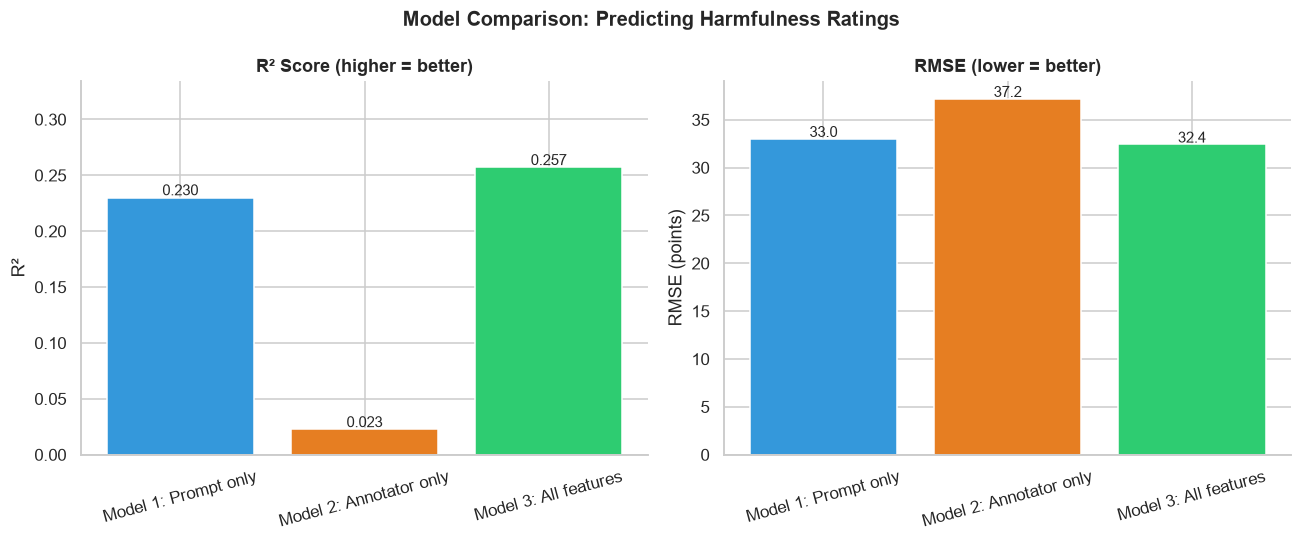

Saved: outputs/fig_model_comparison.png


In [11]:
results = pd.DataFrame({
    'Model'   : ['Model 1: Prompt only',
                 'Model 2: Annotator only',
                 'Model 3: All features'],
    'R²'      : [r2_1, r2_2, r2_3],
    'RMSE'    : [rmse_1, rmse_2, rmse_3],
    'Features': [len(prompt_features),
                 len(annotator_features),
                 len(feature_cols)]
})

print(results.to_string(index=False))

# Visualize
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = ['#3498db', '#e67e22', '#2ecc71']

# R² bar chart
axes[0].bar(results['Model'], results['R²'], color=colors, edgecolor='white')
axes[0].set_title('R² Score (higher = better)', fontweight='bold')
axes[0].set_ylabel('R²')
axes[0].set_ylim(0, max(results['R²']) * 1.3)
axes[0].tick_params(axis='x', rotation=15)
for i, v in enumerate(results['R²']):
    axes[0].text(i, v + 0.002, f'{v:.3f}', ha='center', fontsize=10)
axes[0].spines[['top', 'right']].set_visible(False)

# RMSE bar chart
axes[1].bar(results['Model'], results['RMSE'], color=colors, edgecolor='white')
axes[1].set_title('RMSE (lower = better)', fontweight='bold')
axes[1].set_ylabel('RMSE (points)')
axes[1].tick_params(axis='x', rotation=15)
for i, v in enumerate(results['RMSE']):
    axes[1].text(i, v + 0.2, f'{v:.1f}', ha='center', fontsize=10)
axes[1].spines[['top', 'right']].set_visible(False)

fig.suptitle('Model Comparison: Predicting Harmfulness Ratings',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("outputs/fig_model_comparison.png", bbox_inches='tight')
plt.show()
print("Saved: outputs/fig_model_comparison.png")

## 11. Most Important Features (Model 3)

Which features matter most for predicting ratings?

We look at the **absolute coefficient values** from Model 3.
A large coefficient means that feature has a strong effect on the predicted rating.


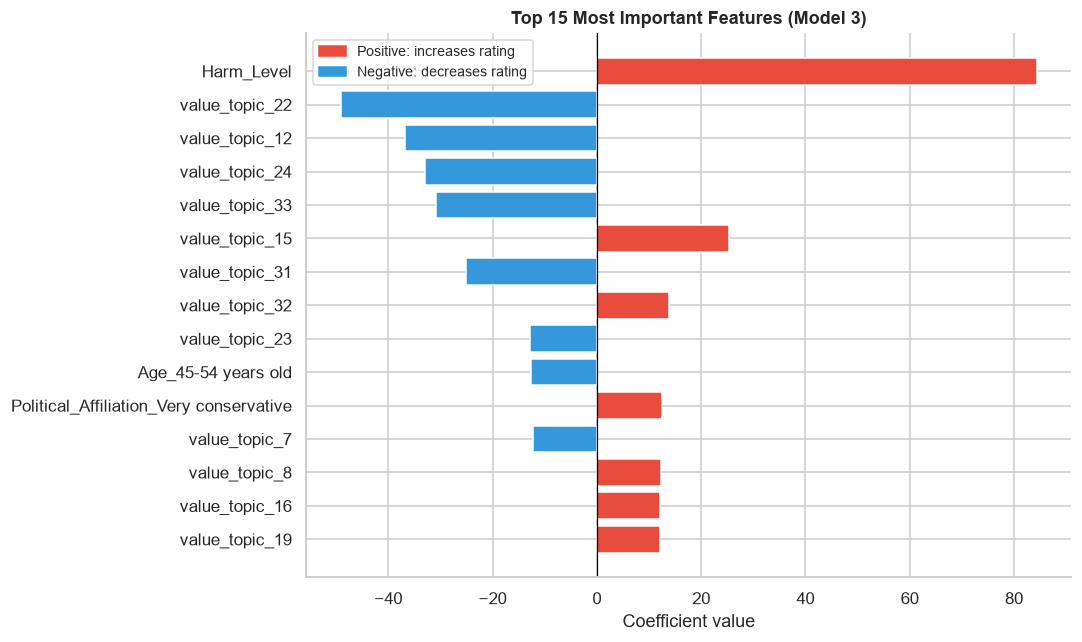

In [12]:
coef_df = pd.DataFrame({
    'feature'    : feature_cols,
    'coefficient': model3.coef_
})
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df = coef_df.sort_values('abs_coef', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 6))
colors_coef = ['#e74c3c' if c > 0 else '#3498db'
               for c in coef_df['coefficient']]
bars = ax.barh(coef_df['feature'][::-1],
               coef_df['coefficient'][::-1],
               color=colors_coef[::-1], edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Top 15 Most Important Features (Model 3)',
             fontweight='bold', fontsize=12)
ax.set_xlabel('Coefficient value')
ax.spines[['top', 'right']].set_visible(False)

from matplotlib.patches import Patch
legend = [Patch(color='#e74c3c', label='Positive: increases rating'),
          Patch(color='#3498db', label='Negative: decreases rating')]
ax.legend(handles=legend, fontsize=9)
plt.tight_layout()
plt.savefig("outputs/fig_top_features.png", bbox_inches='tight')
plt.show()

## 12. Summary

### What we did
1. Converted data from wide format (100 rows) to long format (15,000 rows)
2. Encoded categorical variables using one-hot encoding
3. Built 3 linear regression models with different feature sets
4. Compared models using R² and RMSE

### How to interpret results
- If **Model 1 R² is low** → prompt features alone cannot predict ratings → annotator features are needed
- If **Model 2 R² is low** → annotator features alone cannot predict ratings → prompt features are needed  
- If **Model 3 R² > Model 1 and Model 2** → both groups of features contribute

### Next steps
- [ ] Try more powerful models (Random Forest, Ridge Regression)
- [ ] Add interaction terms (e.g., political affiliation × prompt type)
- [ ] Filter noisy annotators and re-run
- [ ] Mixed-effects model (GLMM) — annotator as random effect


# WE ARE ADDING INTERACTION TERM 


In [15]:
# ── Interaction Term: Factor_1 × Harm_Level ───────────────────

# Add interaction term to long_df
long_df['Factor1_x_HarmLevel'] = long_df['Factor_1'] * long_df['Harm_Level']

# Re-encode with interaction term included
long_df_encoded2 = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

feature_cols2 = [c for c in long_df_encoded2.columns
                 if c not in ['rating', 'Participant_ID']]

X2 = long_df_encoded2[feature_cols2]
y2 = long_df_encoded2['rating']

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

# Train
model_interaction = LinearRegression()
model_interaction.fit(X2_train, y2_train)
pred_int  = model_interaction.predict(X2_test)
r2_int    = r2_score(y2_test, pred_int)
rmse_int  = np.sqrt(mean_squared_error(y2_test, pred_int))

print(f"Model with Factor_1 × Harm_Level interaction:")
print(f"  R²   = {r2_int:.3f}")
print(f"  RMSE = {rmse_int:.2f}")
print()
print(f"Comparison:")
print(f"  Model 3 (no interaction) : R²=0.257")
print(f"  With interaction term    : R²={r2_int:.3f}")
print()

# Coefficient of interaction term
idx = list(feature_cols2).index('Factor1_x_HarmLevel')
coef = model_interaction.coef_[idx]
print(f"Interaction term coefficient: {coef:+.4f}")
if coef > 0:
    print("→ High Factor_1 + High Harm_Level → pushes rating UP")
else:
    print("→ High Factor_1 + High Harm_Level → pushes rating DOWN")

Model with Factor_1 × Harm_Level interaction:
  R²   = 0.261
  RMSE = 32.33

Comparison:
  Model 3 (no interaction) : R²=0.257
  With interaction term    : R²=0.261

Interaction term coefficient: -3.4713
→ High Factor_1 + High Harm_Level → pushes rating DOWN


In [16]:
# ── Interaction Term: Factor_2 × Harm_Level ───────────────────

long_df['Factor2_x_HarmLevel'] = long_df['Factor_2'] * long_df['Harm_Level']

long_df_encoded3 = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

feature_cols3 = [c for c in long_df_encoded3.columns
                 if c not in ['rating', 'Participant_ID']]

X3 = long_df_encoded3[feature_cols3]
y3 = long_df_encoded3['rating']

X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42
)

model_int2 = LinearRegression()
model_int2.fit(X3_train, y3_train)
pred_int2  = model_int2.predict(X3_test)
r2_int2    = r2_score(y3_test, pred_int2)
rmse_int2  = np.sqrt(mean_squared_error(y3_test, pred_int2))

print(f"Model with Factor_2 × Harm_Level interaction:")
print(f"  R²   = {r2_int2:.3f}")
print(f"  RMSE = {rmse_int2:.2f}")

idx2 = list(feature_cols3).index('Factor2_x_HarmLevel')
coef2 = model_int2.coef_[idx2]
print(f"Interaction term coefficient: {coef2:+.4f}")
if coef2 > 0:
    print("→ High empathy + High Harm_Level → pushes rating UP")
else:
    print("→ High empathy + High Harm_Level → pushes rating DOWN")

Model with Factor_2 × Harm_Level interaction:
  R²   = 0.263
  RMSE = 32.29
Interaction term coefficient: +2.4929
→ High empathy + High Harm_Level → pushes rating UP


In [17]:
# ── Interaction Term: Factor_3 × Harm_Level ───────────────────

long_df['Factor3_x_HarmLevel'] = long_df['Factor_3'] * long_df['Harm_Level']

long_df_encoded4 = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

feature_cols4 = [c for c in long_df_encoded4.columns
                 if c not in ['rating', 'Participant_ID']]

X4 = long_df_encoded4[feature_cols4]
y4 = long_df_encoded4['rating']

X4_train, X4_test, y4_train, y4_test = train_test_split(
    X4, y4, test_size=0.2, random_state=42
)

model_int3 = LinearRegression()
model_int3.fit(X4_train, y4_train)
pred_int3  = model_int3.predict(X4_test)
r2_int3    = r2_score(y4_test, pred_int3)
rmse_int3  = np.sqrt(mean_squared_error(y4_test, pred_int3))

print(f"Model with Factor_3 × Harm_Level interaction:")
print(f"  R²   = {r2_int3:.3f}")
print(f"  RMSE = {rmse_int3:.2f}")

idx3 = list(feature_cols4).index('Factor3_x_HarmLevel')
coef3 = model_int3.coef_[idx3]
print(f"Interaction term coefficient: {coef3:+.4f}")
if coef3 > 0:
    print("→ Traditional values + High Harm_Level → pushes rating UP")
else:
    print("→ Traditional values + High Harm_Level → pushes rating DOWN")

Model with Factor_3 × Harm_Level interaction:
  R²   = 0.263
  RMSE = 32.29
Interaction term coefficient: +2.7291
→ Traditional values + High Harm_Level → pushes rating UP


In [18]:
# ── All 3 Interaction Terms Together ─────────────────────────

long_df['Factor1_x_HarmLevel'] = long_df['Factor_1'] * long_df['Harm_Level']
long_df['Factor2_x_HarmLevel'] = long_df['Factor_2'] * long_df['Harm_Level']
long_df['Factor3_x_HarmLevel'] = long_df['Factor_3'] * long_df['Harm_Level']

long_df_encoded5 = pd.get_dummies(long_df, columns=demo_cols, drop_first=True)

feature_cols5 = [c for c in long_df_encoded5.columns
                 if c not in ['rating', 'Participant_ID']]

X5 = long_df_encoded5[feature_cols5]
y5 = long_df_encoded5['rating']

X5_train, X5_test, y5_train, y5_test = train_test_split(
    X5, y5, test_size=0.2, random_state=42
)

model_all_int = LinearRegression()
model_all_int.fit(X5_train, y5_train)
pred_all  = model_all_int.predict(X5_test)
r2_all    = r2_score(y5_test, pred_all)
rmse_all  = np.sqrt(mean_squared_error(y5_test, pred_all))

print(f"Model with ALL 3 interaction terms:")
print(f"  R²   = {r2_all:.3f}")
print(f"  RMSE = {rmse_all:.2f}")
print()
print("Full comparison:")
print(f"  Baseline (no interactions)     : R²=0.257")
print(f"  + Factor_1 × Harm_Level        : R²=0.261")
print(f"  + Factor_2 × Harm_Level        : R²=0.263")
print(f"  + Factor_3 × Harm_Level        : R²=0.263")
print(f"  + All 3 interactions           : R²={r2_all:.3f}")

# Show all 3 coefficients
for term in ['Factor1_x_HarmLevel', 'Factor2_x_HarmLevel', 'Factor3_x_HarmLevel']:
    idx = list(feature_cols5).index(term)
    coef = model_all_int.coef_[idx]
    print(f"  {term}: {coef:+.4f}")

Model with ALL 3 interaction terms:
  R²   = 0.263
  RMSE = 32.29

Full comparison:
  Baseline (no interactions)     : R²=0.257
  + Factor_1 × Harm_Level        : R²=0.261
  + Factor_2 × Harm_Level        : R²=0.263
  + Factor_3 × Harm_Level        : R²=0.263
  + All 3 interactions           : R²=0.263
  Factor1_x_HarmLevel: -4.1869
  Factor2_x_HarmLevel: +1.8688
  Factor3_x_HarmLevel: +2.7291
